# 1. BTC MONDAY EFFECT - HYPOTHESIS DEFINITION & BASELINE BACKTEST

This notebook formulates the quantitative hypothesis and establishes the baseline backtest for the **BTC Monday Effect (v3)** strategy on **hourly BTC/USDT bars (UTC)**.

### 1.1 CORE QUANTITATIVE HYPOTHESIS
- **Weekend-to-Monday flow**: the week "restarts" on Monday; the full 24 h of Monday (Mon 00:00 -> Tue 00:00 UTC) carries a positive drift in Bitcoin. Tested by era in section 4.1-4.2.
- **Only when BTC moves**: on a calm Monday the drift does not cover the round-trip cost. We trade only if ATR(48)% at the Sunday 23:00 close ranks above a percentile of its own last year. It is a *relative* filter, so it should hold across market regimes. Tested by quintiles in section 4.3.
- **Calendar break**: the first Monday of the month (day 1-7) is skipped, since month start/end flows break the pattern. Tested in section 4.4.
- **A young, era-dependent edge**: the effect is expected to be strong in the ETF era, present in the institutional era and absent in the retail era. The era split is therefore part of the hypothesis, not a footnote.

### 1.2 FROZEN STRATEGY RULES
| Rule Component | Specification |
| :--- | :--- |
| **Instrument** | BTC/USDT, 1-hour bars (UTC), Binance data |
| **Volatility Filter** | `ATR(atr_len)% [Sun 23:00 close] >= percentile atr_pctl of its last 8,760 hourly values` |
| **Calendar Filter** | Monday day-of-month `> 7` (first Monday of the month is skipped) |
| **Signal** | Evaluated at the **close** of the Sunday 23:00 UTC bar |
| **Entry** | Buy at the **OPEN** of Monday 00:00 UTC: `Entry = Open * (1 + cost)` |
| **Exit** | Sell at the **OPEN** of Tuesday 00:00 UTC (24 bars later): `Exit = Open * (1 - cost)` |
| **Direction** | Long only, **no stop, no take profit** (position size is the risk management) |
| **Trading Costs** | `cost_bps_per_side` per side (Binance spot: 14 bps = 0.28 % round trip) |
| **Position Sizing** | (a) **100 % of capital** (per-trade reference) · (b) **40 % of capital** (what the robot trades) |

### 1.3 PROVENANCE & REFERENCE VERSIONS
- **Naked Monday**: buy every Monday, no filter. The control group for everything below.
- **v1 (2025, live)**: fixed ATR% band 0.40-1.20 and `|24 h return| <= 4 %`, no calendar filter.
- **v3 (validated)**: translates v1's thresholds to the era (ATR percentile, no cap) and adds the calendar filter. This is the strategy tested here.

### 1.4 STRATEGY PARAMETERS

In [ ]:
VARIANT = "v1_btcusdt"  # only base variants here; see variants/*.yaml

## 2. IMPORTS AND CONFIG

In [2]:
import os
import sys
import json
import importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ---- Paths ----
def find_upwards(name, start=None, must_be_dir=True):
    """Walk up from start (cwd by default) and return the first folder that contains `name`."""
    here = (start or Path.cwd()).resolve()
    for base in (here, *here.parents):
        target = base / name
        if target.is_dir() if must_be_dir else target.exists():
            return base
    raise FileNotFoundError(f"Could not find '{name}' walking up from {here}")

EDGE_DIR   = find_upwards('variants')                  # edge folder (notebooks, engine and variants/ live together)
utils_path = str(find_upwards('utils') / 'utils')      # research_development/utils
for p in (utils_path, str(EDGE_DIR)):
    if p not in sys.path:
        sys.path.insert(0, p)

from utils import compute_metrics
from metrics import sharpe_ratio, max_drawdown
import monday_effect_engine as eng
import variant_config
from variant_config import load_variant, save_json

importlib.reload(eng)   # resets ENGINE_DEFAULTS: nothing leaks between variants

variant_config.EDGE_DIR = EDGE_DIR
assert (variant_config.EDGE_DIR / "variants").is_dir(), f"Doesn't exist {variant_config.EDGE_DIR / 'variants'}"

# ---- Variant config: single source of truth ----
cfg        = load_variant(VARIANT)
eng.set_engine_defaults(**cfg.get("engine_defaults", {}))
RUN_DIR    = cfg["run_dir"]
TICKER     = cfg["instrument"]["ticker"]
DATA_START = cfg["instrument"]["start"]
OOS_START  = cfg["oos_start_ts"]
P          = cfg["params"]
VOL_MODE, ATR_PCTL, ATR_LEN = P["vol_mode"], P["atr_pctl"], P["atr_len"]
SKIP1, ENTRY_HOUR, HOLD, COST_BPS = P["skip_first_monday"], P["entry_hour"], P["hold_bars"], P["cost_bps_per_side"]
SIZE_FRAC  = eng.ENGINE_DEFAULTS["size_fraction"]
PPY        = 365    # BTC trades every day: annualisation for Sharpe

# Frozen rules, passed as-is to every backtest call in this notebook
RULES = dict(vol_mode=VOL_MODE, atr_pctl=ATR_PCTL, atr_len=ATR_LEN, skip_first_monday=SKIP1,
             entry_hour=ENTRY_HOUR, hold_bars=HOLD, cost_bps_per_side=COST_BPS)

print("Imports complete.")
print(f"Loaded monday_effect_engine from: {eng.__file__}")
print(f"Edge dir: {EDGE_DIR}")
print(f"Variant: {cfg['id']} | {TICKER} | ATR({ATR_LEN})% >= P{ATR_PCTL:g} of {eng.ENGINE_DEFAULTS['pctl_window']} bars | "
      f"skip first Monday={SKIP1} | {COST_BPS:g} bps/side | size {SIZE_FRAC:.0%}")
print(f"Data source: {eng.ENGINE_DEFAULTS['data_source']} | swap: {eng.ENGINE_DEFAULTS['financing_bps_per_night']:g} bps/night")
print(f"Run folder: {RUN_DIR}")

FileNotFoundError: No 'v1_.yaml' found under /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/Monday_Effect/variants

## 3. LOAD DATA AND IN-SAMPLE / OUT-OF-SAMPLE

In [ ]:
df_raw = eng.load_data(TICKER, start=DATA_START)
print(len(df_raw), "hourly bars |", df_raw.index[0], "->", df_raw.index[-1])
print(df_raw.groupby(df_raw.index.year).size().to_dict())

# Indicators are computed ONCE on the full history, so slicing IS/OOS keeps the percentile warm-up
df = eng.prepare(df_raw, atr_len=ATR_LEN, entry_hour=ENTRY_HOUR)

n_is = int((df.index < OOS_START).sum())
df_is, df_oos = df.iloc[:n_is].copy(), df.iloc[n_is:].copy()
assert len(df_is) > 0 and len(df_oos) > 0, "Check split.oos_start against the history of this ticker."
oos_start = df_oos.index[0]

mondays = df[df["entry_ok"]]
print("=" * 70)
print("DATA INGESTION & DATASET SPLIT")
print("=" * 70)
print(f"Total Prepared Bars: {len(df):,} ({df.index.min():%Y-%m-%d} to {df.index.max():%Y-%m-%d})")
print(f"In-Sample (IS, {len(df_is)/len(df)*100:.1f}%): {len(df_is):,} bars ({df_is.index.min():%Y-%m-%d} to {df_is.index.max():%Y-%m-%d})")
print(f"Out-of-Sample (OOS, {len(df_oos)/len(df)*100:.1f}%): {len(df_oos):,} bars ({df_oos.index.min():%Y-%m-%d} to {df_oos.index.max():%Y-%m-%d})")
print(f"Mondays with a valid signal bar: {len(mondays)} | with percentile warm-up done: {int(mondays['atr_rank'].notna().sum())}")
print("=" * 70)
df[["open", "high", "low", "close", "atr_pct"]].tail()

80312 hourly bars | 2017-08-17 04:00:00 -> 2026-10-20 19:00:00
{2017: 3278, 2018: 8698, 2019: 8732, 2020: 8766, 2021: 8747, 2022: 8760, 2023: 8759, 2024: 8784, 2025: 8760, 2026: 7028}
DATA INGESTION & DATASET SPLIT
Total Prepared Bars: 80,312 (2017-08-17 to 2026-10-20)
In-Sample (IS, 69.6%): 55,908 bars (2017-08-17 to 2024-01-07)
Out-of-Sample (OOS, 30.4%): 24,404 bars (2024-01-08 to 2026-10-20)
Mondays with a valid signal bar: 479 | with percentile warm-up done: 452


,open,high,low,close,atr_pct
time,,,,,
2026-10-20 15:00:00,83276.76,83306.85,82211.21,82617.68,0.501236
2026-10-20 16:00:00,82617.68,82842.01,82337.54,82778.39,0.507301
2026-10-20 17:00:00,82778.40,82929.00,82692.84,82820.33,0.509317
2026-10-20 18:00:00,82820.33,82829.03,82465.26,82538.73,0.515271
2026-10-20 19:00:00,82538.73,82664.01,82393.77,82606.01,0.511369


## 4. EXPLORATORY CHECKS OF THE HYPOTHESIS (EDGE-SPECIFIC)

The four claims of section 1.1, checked on the data before any backtest. **Gross** = no costs, **net** = with `cost_bps_per_side`.

### 4.1 IS MONDAY SPECIAL? DAY-OF-WEEK RETURN BY ERA

In [ ]:
ERAS = {"Retail (2017-19)": (2017, 2019), "Institutional (2020-23)": (2020, 2023), "ETF (2024+)": (2024, 2100)}
def era_of(y):
    return next(k for k, (a, b) in ERAS.items() if a <= y <= b)

def tstat(x):
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    return float(x.mean() / (x.std(ddof=1) / np.sqrt(len(x)))) if len(x) > 2 and x.std(ddof=1) > 0 else np.nan

# Open-to-open return of each UTC calendar day (gross)
d_open = df_raw["open"].resample("D").first()
d_ret = ((d_open.shift(-1) / d_open - 1) * 100).dropna()
eda = pd.DataFrame({"ret": d_ret, "dow": d_ret.index.dayofweek, "era": [era_of(y) for y in d_ret.index.year]})
DAY = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

dow_tbl = eda.pivot_table(index="dow", columns="era", values="ret", aggfunc="mean")[list(ERAS)]
dow_tbl["All"] = eda.groupby("dow")["ret"].mean()
dow_tbl.index = DAY
print("=" * 70)
print("AVERAGE DAILY RETURN BY DAY OF WEEK AND ERA (%, gross, open-to-open UTC)")
print("=" * 70)
display(dow_tbl.round(3))
print("Best day of the week per era:", {c: dow_tbl[c].idxmax() for c in dow_tbl.columns})

AVERAGE DAILY RETURN BY DAY OF WEEK AND ERA (%, gross, open-to-open UTC)


era,Retail (2017-19),Institutional (2020-23),ETF (2024+),All
Mon,0.343,0.377,0.509,0.409
Tue,-0.222,0.309,-0.272,-0.006
Wed,0.277,0.483,0.384,0.399
Thu,-0.385,-0.133,-0.221,-0.225
Fri,0.601,0.142,0.112,0.252
Sat,0.394,0.096,0.003,0.145
Sun,0.072,0.029,0.146,0.076


Best day of the week per era: {'Retail (2017-19)': 'Fri', 'Institutional (2020-23)': 'Wed', 'ETF (2024+)': 'Mon', 'All': 'Mon'}


### 4.2 NAKED MONDAY BY ERA (EVERY MONDAY, NO FILTER)

In [ ]:
naked_kw = dict(vol_mode="none", skip_first_monday=False, atr_len=ATR_LEN, entry_hour=ENTRY_HOUR, hold_bars=HOLD)
naked_g = eng.run_monday_backtest(df, cost_bps_per_side=0.0, **naked_kw)        # gross
naked_n = eng.run_monday_backtest(df, cost_bps_per_side=COST_BPS, **naked_kw)   # net
for t in (naked_g, naked_n):
    t["era"] = [era_of(y) for y in pd.to_datetime(t["entry_time"]).dt.year]

rows = []
for era in list(ERAS) + ["All"]:
    g = naked_g if era == "All" else naked_g[naked_g["era"] == era]
    n = naked_n if era == "All" else naked_n[naked_n["era"] == era]
    rows.append({"Era": era, "Mondays": len(g), "Gross mean %": g["pnl"].mean(), "Gross t": tstat(g["pnl"]),
                 "Net mean %": n["pnl"].mean(), "Net t": tstat(n["pnl"]), "Hit rate %": (n["pnl"] > 0).mean() * 100})
naked_tbl = pd.DataFrame(rows).set_index("Era")
print("=" * 70)
print(f"NAKED MONDAY BY ERA (net = {COST_BPS:g} bps/side)")
print("=" * 70)
display(naked_tbl.round(3))

NAKED MONDAY BY ERA (net = 14 bps/side)


,Mondays,Gross mean %,Gross t,Net mean %,Net t,Hit rate %
Era,,,,,,
Retail (2017-19),123,0.321,0.785,0.041,0.099,41.463
Institutional (2020-23),206,0.356,1.197,0.075,0.253,46.602
ETF (2024+),147,0.509,2.160,0.228,0.970,51.020
All,476,0.394,2.174,0.113,0.627,46.639


### 4.3 DOES VOLATILITY MATTER? ATR% RANK QUINTILES (EDA BY QUINTILES)

Each Monday is placed in a quintile of its `atr_rank` (how high the Sunday-23:00 ATR% sits within its last year). The filter hypothesis says the net return should rise with the quintile and that the lowest ones should not cover costs.

NET MONDAY RETURN BY ATR% RANK QUINTILE (whole history)


,Mondays,rank_from,rank_to,net_mean,hit,net_t
quintile,,,,,,
Q1 calm,90,0.000,0.030,-0.096,43.333,-0.349
Q2,90,0.031,0.109,-0.713,35.556,-2.414
Q3,89,0.111,0.249,-0.475,42.697,-1.390
Q4,90,0.249,0.554,1.221,61.111,3.283
Q5 wild,90,0.562,0.986,0.501,48.889,0.853


Spearman rho (atr_rank vs net Monday return): +0.112 (p = 0.018)
Filter threshold: atr_rank >= 0.30  ->  trades the top 70% of Mondays
Spearman rho, ETF era only (147 Mondays): +0.273 (p = 0.001)


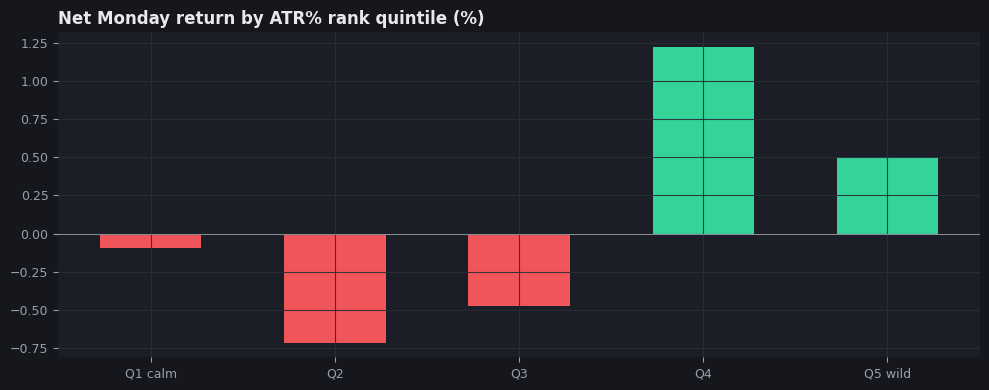

In [ ]:
q = naked_n.dropna(subset=["atr_rank"]).copy()
q["quintile"] = pd.qcut(q["atr_rank"], 5, labels=["Q1 calm", "Q2", "Q3", "Q4", "Q5 wild"])
qt = q.groupby("quintile", observed=True).agg(Mondays=("pnl", "size"), rank_from=("atr_rank", "min"), rank_to=("atr_rank", "max"),
                                              net_mean=("pnl", "mean"), hit=("win", "mean"))
qt["net_t"] = q.groupby("quintile", observed=True)["pnl"].apply(tstat)
qt["hit"] *= 100
rho, p_rho = stats.spearmanr(q["atr_rank"], q["pnl"])
print("=" * 70)
print("NET MONDAY RETURN BY ATR% RANK QUINTILE (whole history)")
print("=" * 70)
display(qt.round(3))
print(f"Spearman rho (atr_rank vs net Monday return): {rho:+.3f} (p = {p_rho:.3f})")
print(f"Filter threshold: atr_rank >= {ATR_PCTL/100:.2f}  ->  trades the top {100 - ATR_PCTL:g}% of Mondays")

# same table inside the ETF era only (is the volatility effect era-specific?)
q_etf = q[q["era"] == "ETF (2024+)"]
if len(q_etf) >= 25:
    rho_e, p_e = stats.spearmanr(q_etf["atr_rank"], q_etf["pnl"])
    print(f"Spearman rho, ETF era only ({len(q_etf)} Mondays): {rho_e:+.3f} (p = {p_e:.3f})")

BG, PANEL, GRIDC, TXT, SUB, GREEN, RED, ORANGE = "#15171c", "#1b1e26", "#2a2d37", "#e8e9ec", "#9aa0ab", "#34d399", "#f0555a", "#f5a524"
def dark_ax(ax):
    ax.set_facecolor(PANEL); ax.grid(True, color=GRIDC, lw=0.8, alpha=0.9)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.tick_params(colors=SUB, labelsize=9)

fig, ax = plt.subplots(figsize=(10, 4), facecolor=BG)
dark_ax(ax)
ax.bar(range(len(qt)), qt["net_mean"], color=[GREEN if v > 0 else RED for v in qt["net_mean"]], width=0.55)
ax.axhline(0, color=SUB, lw=0.6)
ax.set_xticks(range(len(qt))); ax.set_xticklabels(qt.index, color=SUB)
ax.set_title("Net Monday return by ATR% rank quintile (%)", color=TXT, fontweight="bold", loc="left")
plt.tight_layout(); plt.show()

### 4.4 FIRST MONDAY OF THE MONTH VS THE REST

In [ ]:
naked_n["first_monday"] = pd.to_datetime(naked_n["entry_time"]).dt.day <= 7
fm = naked_n.pivot_table(index="era", columns="first_monday", values="pnl", aggfunc=["mean", "size"])
fm = fm.reindex(list(ERAS))
fm_tbl = pd.DataFrame({"Rest: mean %": fm[("mean", False)], "Rest: N": fm[("size", False)],
                       "First Monday: mean %": fm[("mean", True)], "First Monday: N": fm[("size", True)]})
print("=" * 70)
print("NET MONDAY RETURN: FIRST MONDAY OF THE MONTH VS THE REST (by era)")
print("=" * 70)
display(fm_tbl.round(3))
print("All eras | first Monday mean %:", round(naked_n.loc[naked_n["first_monday"], "pnl"].mean(), 3),
      "| rest mean %:", round(naked_n.loc[~naked_n["first_monday"], "pnl"].mean(), 3))

NET MONDAY RETURN: FIRST MONDAY OF THE MONTH VS THE REST (by era)


,Rest: mean %,Rest: N,First Monday: mean %,First Monday: N
era,,,,
Retail (2017-19),0.422,95,-1.253,28
Institutional (2020-23),-0.054,158,0.498,48
ETF (2024+),0.348,113,-0.170,34


All eras | first Monday mean %: -0.154 | rest mean %: 0.194


## 5. BASELINE BACKTEST WITH FROZEN RULES

PERFORMANCE SUMMARY (NET OF 14 BPS PER SIDE · daily MTM drawdown, Sharpe annualised x365)


,Period,Sizing,Trades,Win Rate,Profit Factor,Expectancy,Total Return,CAGR,Sharpe,Max Drawdown
0,In-Sample (2017-2024),100% Capital,88,48.9%,1.475,0.779%,74.1%,9.1%,0.52,-24.93%
1,In-Sample (2017-2024),40% Capital (robot),88,48.9%,1.475,0.312%,28.4%,4.0%,0.52,-10.70%
2,Out-of-Sample (2024-2026),100% Capital,38,65.8%,3.948,1.334%,63.3%,19.3%,1.63,-3.68%
3,Out-of-Sample (2024-2026),40% Capital (robot),38,65.8%,3.948,0.534%,22.3%,7.5%,1.66,-1.47%
4,Full Period (2017-2026),100% Capital,126,54.0%,1.738,0.947%,184.2%,12.1%,0.71,-24.93%
5,Full Period (2017-2026),40% Capital (robot),126,54.0%,1.738,0.379%,57.0%,5.0%,0.72,-10.70%


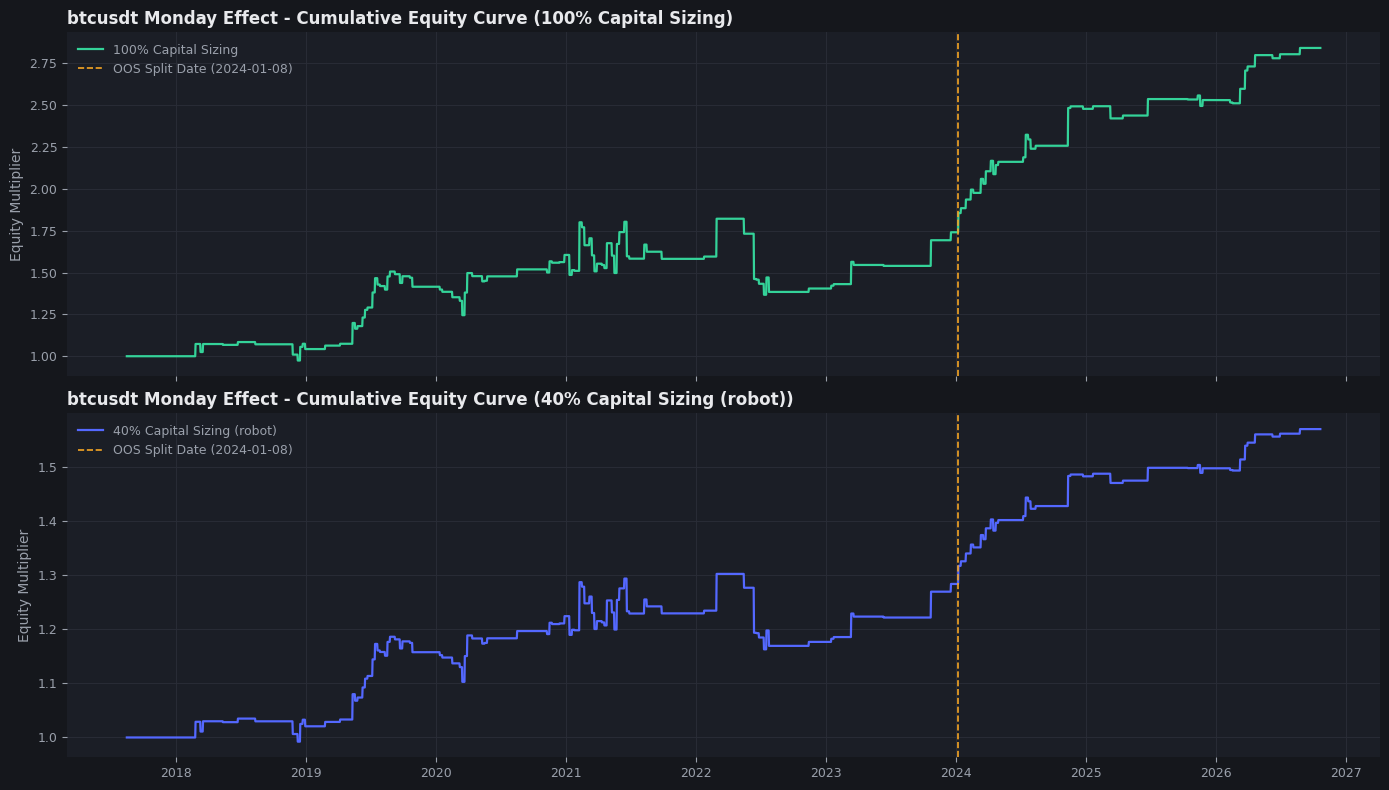

In [ ]:
trades_is  = eng.run_monday_backtest(df_is,  **RULES)
trades_oos = eng.run_monday_backtest(df_oos, **RULES)
trades_all = eng.run_monday_backtest(df,     **RULES)

def sized(t, sizing):
    return t if sizing == "capital" else t.assign(pnl=t["pnl_frac"], win=t["pnl_frac"] > 0)

def perf_row(t, price_df, period, sizing):
    m = compute_metrics(sized(t, sizing), contract_multiplier=1.0, cost_per_trade=0.0)
    ret = eng.daily_returns(price_df, t, sizing=sizing)
    eq = (1.0 + ret).cumprod()
    yrs = (price_df.index[-1] - price_df.index[0]).days / 365.25
    return {"Period": period, "Sizing": "100% Capital" if sizing == "capital" else f"{SIZE_FRAC:.0%} Capital (robot)",
            "Trades": m["num_trades"], "Win Rate": f"{m['win_rate']:.1f}%", "Profit Factor": f"{m['profit_factor']:.3f}",
            "Expectancy": f"{m['expectancy']:.3f}%", "Total Return": f"{(eq.iloc[-1] - 1) * 100:.1f}%",
            "CAGR": f"{((eq.iloc[-1] ** (1 / yrs)) - 1) * 100:.1f}%" if yrs > 0 else "n/a",
            "Sharpe": f"{sharpe_ratio(ret, periods_per_year=PPY):.2f}", "Max Drawdown": f"{max_drawdown(eq) * 100:.2f}%"}

periods = [(f"In-Sample ({df_is.index[0].year}-{df_is.index[-1].year})", trades_is, df_is),
           (f"Out-of-Sample ({df_oos.index[0].year}-{df_oos.index[-1].year})", trades_oos, df_oos),
           (f"Full Period ({df.index[0].year}-{df.index[-1].year})", trades_all, df)]
perf_table = pd.DataFrame([perf_row(t, d, name, s) for name, t, d in periods for s in ("capital", "fraction")])

print("=" * 80)
print(f"PERFORMANCE SUMMARY (NET OF {COST_BPS:g} BPS PER SIDE · daily MTM drawdown, Sharpe annualised x{PPY})")
print("=" * 80)
display(perf_table)

ret_cap = eng.daily_returns(df, trades_all, sizing="capital")
ret_fr = eng.daily_returns(df, trades_all, sizing="fraction")
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, facecolor=BG)
for ax, r, col, lab in ((ax1, ret_cap, GREEN, "100% Capital Sizing"), (ax2, ret_fr, "#5468ff", f"{SIZE_FRAC:.0%} Capital Sizing (robot)")):
    dark_ax(ax)
    ax.plot(r.index, (1 + r).cumprod(), color=col, lw=1.6, label=lab)
    ax.axvline(oos_start, color=ORANGE, ls="--", lw=1.2, label=f"OOS Split Date ({oos_start:%Y-%m-%d})")
    ax.set_title(f"{TICKER} Monday Effect - Cumulative Equity Curve ({lab})", color=TXT, fontweight="bold", loc="left")
    ax.set_ylabel("Equity Multiplier", color=SUB)
    ax.legend(frameon=False, labelcolor=SUB, fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()

## 6. SANITY CHECKS & VERIFICATION

In [ ]:
print("=" * 70)
print("SANITY CHECKS & REPRODUCIBILITY")
print("=" * 70)

# 1. No lookahead + execution model
prev_end = None
for idx_, r in trades_all.iterrows():
    et, xt = pd.Timestamp(r["entry_time"]), pd.Timestamp(r["exit_time"])
    sig_time = df.index[int(r["i_ent"]) - 1]
    assert sig_time == et - pd.Timedelta(hours=1), f"Signal bar is not the previous hour at trade {idx_}!"
    assert df.index[int(r["i_ent"])] == et and df.index[int(r["i_sal"])] == xt, f"i_ent / i_sal misaligned at trade {idx_}!"
    assert et.dayofweek == 0 and et.hour == ENTRY_HOUR, f"Entry is not Monday {ENTRY_HOUR}:00 at trade {idx_}!"
    assert xt - et == pd.Timedelta(hours=HOLD), f"Holding is not {HOLD} h at trade {idx_}!"
    if SKIP1:
        assert et.day > 7, f"First Monday traded at trade {idx_}!"
    assert np.isclose(r["entry_price"], df.loc[et, "open"] * (1 + COST_BPS / 1e4), atol=1e-6), f"Entry price mismatch at trade {idx_}!"
    assert prev_end is None or et >= prev_end, f"Overlapping trades at {idx_}!"
    prev_end = xt
print(f"Sanity Check 1: PASSED. No lookahead, Monday {ENTRY_HOUR:02d}:00 UTC entry, {HOLD} h hold, no overlap across all {len(trades_all)} trades.")
print("   - Signal evaluated at the close of the previous hourly bar (Sunday 23:00 UTC).")
print(f"   - Execution at the open with +{COST_BPS:.0f} bps per side.")

# 2. Trade distribution per calendar year
trades_all["year"] = pd.to_datetime(trades_all["entry_time"]).dt.year
tpy = trades_all.groupby("year").size()
print("\nSanity Check 2: Trade Frequency per Year:")
print(f"   - Average trades per year: {tpy.mean():.1f}")
print(f"   - Min trades: {tpy.min()} ({tpy.idxmin()}) | Max trades: {tpy.max()} ({tpy.idxmax()})")

# 3. MTM paths reproduce the trade returns exactly
paths = eng.trade_mtm_paths(df, trades_all, sizing="capital")
err = max(abs(np.prod(1 + p) - (1 + pnl / 100)) for p, pnl in zip(paths, trades_all["pnl"]))
print(f"\nSanity Check 3: MTM paths telescope to trade returns (max abs error {err:.2e}).")
assert err < 1e-9

# 4. Cross-check with the reference figures published for the v3 rules (Sentinel engine, Binance + Coinbase data)
is_reference = (VOL_MODE, ATR_PCTL, ATR_LEN, SKIP1, ENTRY_HOUR, HOLD) == ("pctl", 30.0, 48, True, 0, 24)
REF = {"n_all": 183, "pf_all": 1.51, "n_oos": 56, "pf_oos": 2.70}
if is_reference:
    m_a, m_o = compute_metrics(trades_all, 1.0), compute_metrics(trades_oos, 1.0)
    comp = pd.DataFrame([
        {"Metric": "Trades, full period", "Engine (ours)": len(trades_all), "Reference": REF["n_all"]},
        {"Metric": "Profit Factor, full period", "Engine (ours)": round(m_a["profit_factor"], 3), "Reference": REF["pf_all"]},
        {"Metric": "Trades, OOS", "Engine (ours)": len(trades_oos), "Reference": REF["n_oos"]},
        {"Metric": "Profit Factor, OOS", "Engine (ours)": round(m_o["profit_factor"], 3), "Reference": REF["pf_oos"]}])
    print("\nSanity Check 4: Comparison with the published reference (Sentinel):")
    display(comp)
    print("   Differences are expected if the CSV is Binance-only (the reference also uses Coinbase before Binance's start)\n"
          "   or if pctl_min_bars differs; a large gap in the OOS block (same data) would point to a rule discrepancy.")
else:
    print("\nSanity Check 4: skipped (not the reference v3 rules).")

SANITY CHECKS & REPRODUCIBILITY
Sanity Check 1: PASSED. No lookahead, Monday 00:00 UTC entry, 24 h hold, no overlap across all 126 trades.
   - Signal evaluated at the close of the previous hourly bar (Sunday 23:00 UTC).
   - Execution at the open with +14 bps per side.

Sanity Check 2: Trade Frequency per Year:
   - Average trades per year: 14.0
   - Min trades: 7 (2023) | Max trades: 23 (2021)

Sanity Check 3: MTM paths telescope to trade returns (max abs error 1.11e-15).

Sanity Check 4: Comparison with the published reference (Sentinel):


,Metric,Engine (ours),Reference
0,"Trades, full period",126.000,183.00
1,"Profit Factor, full period",1.738,1.51
2,"Trades, OOS",38.000,56.00
3,"Profit Factor, OOS",3.948,2.70


   Differences are expected if the CSV is Binance-only (the reference also uses Coinbase before Binance's start)
   or if pctl_min_bars differs; a large gap in the OOS block (same data) would point to a rule discrepancy.


## 7. REFERENCE VARIANTS: NAKED MONDAY VS v1 VS v3 (SAME BARS, SAME COSTS, SAME SIZE)

VARIANT COMPARISON (40% capital per trade, 14 bps/side)


,Variant,Trades,Win Rate,Profit Factor,Sharpe,Max Drawdown,Final Capital
0,Naked Monday (no filter),476,46.6%,1.085,0.20,-25.62%,1.17x
1,"v1 (ATR band 0.40-1.20, |ret24h| <= 4%)",250,49.2%,1.220,0.39,-18.04%,1.26x
2,"v3 (configured: P30, skip 1st Monday)",126,54.0%,1.738,0.72,-10.70%,1.57x


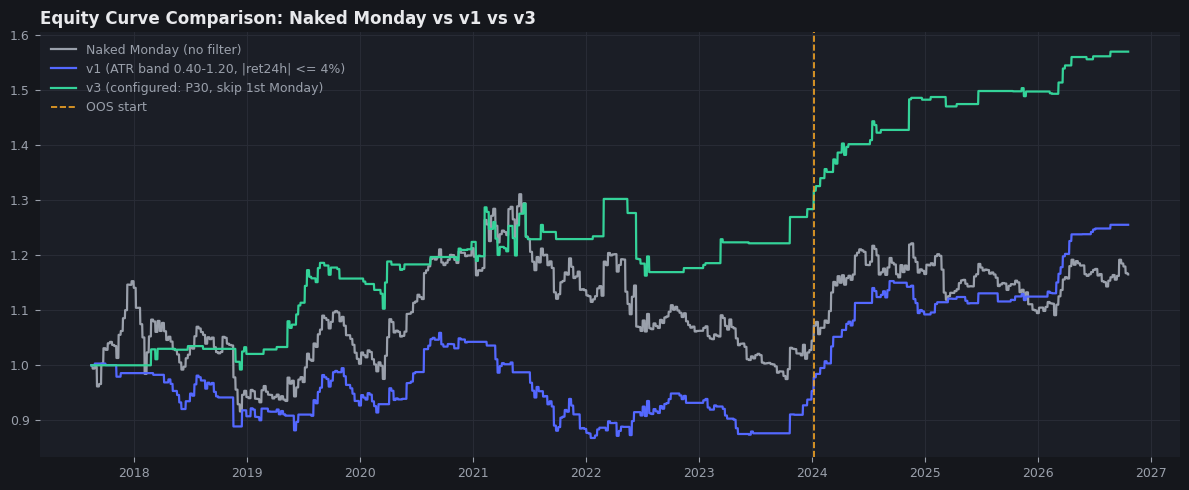

In [ ]:
v_naked = eng.run_monday_backtest(df, cost_bps_per_side=COST_BPS, **naked_kw)
v_v1 = eng.run_monday_backtest(df, vol_mode="band", atr_band=(0.40, 1.20), max_abs_ret24_pct=4.0, skip_first_monday=False,
                               atr_len=ATR_LEN, entry_hour=ENTRY_HOUR, hold_bars=HOLD, cost_bps_per_side=COST_BPS)
variants = {"Naked Monday (no filter)": v_naked, "v1 (ATR band 0.40-1.20, |ret24h| <= 4%)": v_v1, f"v3 (configured: P{ATR_PCTL:g}, skip 1st Monday)": trades_all}

rows, curves = [], {}
for name, t in variants.items():
    m = compute_metrics(sized(t, "fraction"), 1.0, 0.0)
    r = eng.daily_returns(df, t, sizing="fraction")
    eq = (1 + r).cumprod()
    curves[name] = eq
    rows.append({"Variant": name, "Trades": m["num_trades"], "Win Rate": f"{m['win_rate']:.1f}%",
                 "Profit Factor": f"{compute_metrics(t, 1.0)['profit_factor']:.3f}", "Sharpe": f"{sharpe_ratio(r, periods_per_year=PPY):.2f}",
                 "Max Drawdown": f"{max_drawdown(eq) * 100:.2f}%", "Final Capital": f"{eq.iloc[-1]:.2f}x"})
print("=" * 80)
print(f"VARIANT COMPARISON ({SIZE_FRAC:.0%} capital per trade, {COST_BPS:g} bps/side)")
print("=" * 80)
display(pd.DataFrame(rows))

fig, ax = plt.subplots(figsize=(12, 5), facecolor=BG)
dark_ax(ax)
for (name, eq), col in zip(curves.items(), (SUB, "#5468ff", GREEN)):
    ax.plot(eq.index, eq, color=col, lw=1.6, label=name)
ax.axvline(oos_start, color=ORANGE, ls="--", lw=1.2, label="OOS start")
ax.set_title("Equity Curve Comparison: Naked Monday vs v1 vs v3", color=TXT, fontweight="bold", loc="left")
ax.legend(frameon=False, labelcolor=SUB, fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()

## 8. SUMMARY OF HYPOTHESIS & NEXT STEPS

In [ ]:
m_all, m_is, m_oos = (compute_metrics(t, 1.0, 0.0) for t in (trades_all, trades_is, trades_oos))
t_all = tstat(trades_all["pnl"])
ret_fr_all = eng.daily_returns(df, trades_all, sizing="fraction")
max_dd_fr = max_drawdown((1 + ret_fr_all).cumprod()) * 100
years = (df.index[-1] - df.index[0]).days / 365.25
next_nb = "02_Monday_Optimization.ipynb"

PF_MIN, T_MIN, N_MIN = 1.3, 2.0, 100
confirmed = (m_all["profit_factor"] >= PF_MIN and m_oos["profit_factor"] >= PF_MIN and t_all >= T_MIN and m_all["num_trades"] >= N_MIN)
verdict = "Hypothesis Confirmed" if confirmed else "Hypothesis NOT clearly confirmed"
etf_row = naked_tbl.loc["ETF (2024+)"] if "ETF (2024+)" in naked_tbl.index else None

print("=" * 80)
print("8. SUMMARY OF HYPOTHESIS & NEXT STEPS")
print("=" * 80)
print(f"""
Key Findings:

1. {verdict} (criteria: PF >= {PF_MIN} full and OOS, t-stat >= {T_MIN}, N >= {N_MIN}): {m_all['num_trades']} trades over {years:.0f}+ years,
   win rate {m_all['win_rate']:.1f}%, Profit Factor {m_all['profit_factor']:.3f} (IS {m_is['profit_factor']:.3f} / OOS {m_oos['profit_factor']:.3f}), t-stat of the mean trade {t_all:.2f}.

2. Era dependence: naked-Monday net mean by era -> """ + "; ".join(f"{e}: {naked_tbl.loc[e, 'Net mean %']:+.3f}% (t={naked_tbl.loc[e, 'Net t']:.2f})" for e in ERAS) + f""".

3. Volatility: Spearman rho between ATR% rank and net Monday return = {rho:+.3f} (p = {p_rho:.3f}).

4. Risk at {SIZE_FRAC:.0%} sizing: max daily-MTM drawdown {max_dd_fr:.2f}% over {df.index[0].year}-{df.index[-1].year}.

5. Next Step: proceed to {next_nb} to check that (P{ATR_PCTL:g}, ATR({ATR_LEN})) sits on a broad, stable plateau on in-sample data.
""")

8. SUMMARY OF HYPOTHESIS & NEXT STEPS

Key Findings:

1. Hypothesis Confirmed (criteria: PF >= 1.3 full and OOS, t-stat >= 2.0, N >= 100): 126 trades over 9+ years,
   win rate 54.0%, Profit Factor 1.738 (IS 1.475 / OOS 3.948), t-stat of the mean trade 2.19.

2. Era dependence: naked-Monday net mean by era -> Retail (2017-19): +0.041% (t=0.10); Institutional (2020-23): +0.075% (t=0.25); ETF (2024+): +0.228% (t=0.97).

3. Volatility: Spearman rho between ATR% rank and net Monday return = +0.112 (p = 0.018).

4. Risk at 40% sizing: max daily-MTM drawdown -10.70% over 2017-2026.

5. Next Step: proceed to 02_Monday_Optimization.ipynb to check that (P30, ATR(48)) sits on a broad, stable plateau on in-sample data.



## 9. SAVE THE RESULTS OF THIS NOTEBOOK FOR THE VARIANT

In [ ]:
save_json(cfg, "01_hypothesis.json", {
    "variant": cfg["id"],
    "ticker": TICKER,
    "params": cfg["params"],
    "oos_start": str(oos_start.date()),
    "all": {"n": int(len(trades_all)), "pf": float(m_all["profit_factor"]), "win_rate": float(m_all["win_rate"]), "t_stat": float(t_all)},
    "is":  {"n": int(len(trades_is)),  "pf": float(m_is["profit_factor"])},
    "oos": {"n": int(len(trades_oos)), "pf": float(m_oos["profit_factor"])},
    "max_dd_fraction_sizing_pct": float(max_dd_fr),
    "naked_by_era": naked_tbl.round(4).reset_index().to_dict(orient="records"),
    "atr_rank_spearman": {"rho": float(rho), "p": float(p_rho)},
    "hypothesis_confirmed": bool(confirmed),
})

Saved: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/notebooks/Monday_Effect/runs/base_btcusdt/01_hypothesis.json


PosixPath('/Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/notebooks/Monday_Effect/runs/base_btcusdt/01_hypothesis.json')

## 10. SIGNAL PARITY

In [ ]:
BASE_VARIANT = None   # base variant: yaml name without .yaml (e.g. "base_btcusdt" in a CFD variant). In the base itself: None
if BASE_VARIANT:
    cb = load_variant(BASE_VARIANT)
    diff = {k: (cb["params"].get(k), cfg["params"].get(k)) for k in set(cb["params"]) | set(cfg["params"])
            if cb["params"].get(k) != cfg["params"].get(k)}
    if diff:
        print("Params that differ (base, variant):")
        for k, (bv, vv) in sorted(diff.items()):
            print(f"  {k}: {bv} vs {vv}")
    # Same data, each variant with ITS OWN rules and costs
    pb = cb["params"]
    db = eng.prepare(df_raw, atr_len=pb["atr_len"], entry_hour=pb["entry_hour"])
    tb = eng.run_monday_backtest(db, vol_mode=pb["vol_mode"], atr_pctl=pb["atr_pctl"], atr_len=pb["atr_len"],
                                 skip_first_monday=pb["skip_first_monday"], entry_hour=pb["entry_hour"],
                                 hold_bars=pb["hold_bars"], cost_bps_per_side=pb["cost_bps_per_side"],
                                 financing_bps_per_night=cb.get("engine_defaults", {}).get("financing_bps_per_night", 0.0))
    tv = trades_all
    both = pd.Index(tv["entry_time"]).intersection(pd.Index(tb["entry_time"]))
    print(f"trades base/variant: {len(tb)}/{len(tv)} | entries shared: {len(both)} "
          f"({len(both) / max(len(tv), 1):.0%} of variant, {len(both) / max(len(tb), 1):.0%} of base)")
    print(f"PF base/variant: {compute_metrics(tb, 1.0)['profit_factor']:.3f} / {compute_metrics(tv, 1.0)['profit_factor']:.3f}")
else:
    print("BASE_VARIANT is None: nothing to compare.")

BASE_VARIANT is None: nothing to compare.
